# RT-IoT2022 - One-Class SVM (Support Vector Machine)

Now we are going to apply the One-Class SVM to detect anomalous IoT traffic. The main steps are:

- load the preprocessed datasets
- train a baseline model with the default hyperparameters
- study the effect of 'nu' and 'gamma' on the validation set 
- select the best configuration
- evaluate the selected model once on the test set
- analyze which attacks are detected and which normal traffic causes false alarms

The model is trained only on normal traffic. It learns a boundary around normal behaviour: everything outside this boundary is classified as an anomaly.

In scikit-learn the model returns '-1' for anomalies and '+1' for normal samples, so we convert the predictions to '1' = anomaly and '0' = normal

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)



In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

train_metadata = pd.read_csv("../data/processed/train_metadata.csv")
val_metadata = pd.read_csv("../data/processed/val_metadata.csv")
test_metadata = pd.read_csv("../data/processed/test_metadata.csv")

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (7209, 92)
Validation set: (55356, 92)
Test set: (55357, 92)


In [3]:
y_val = (val_metadata["Label"] == "Anomaly").astype(int)
y_test = (test_metadata["Label"] == "Anomaly").astype(int)

print("Validation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Validation labels:
Label
1    52953
0     2403
Name: count, dtype: int64

Test labels:
Label
1    52954
0     2403
Name: count, dtype: int64


### Baseline model

We first train the model with the default hyperparameters ('nu = 0.5', 'gamma = "scale" ') and evaluate it on the validation set. This is the reference point for the hyperparameters analysis.

In [4]:
baseline_model = OneClassSVM()
baseline_model.fit(X_train)
baseline_predictions = baseline_model.predict(X_val)

baseline_predictions = (baseline_predictions == -1).astype(int)

In [5]:
cm = confusion_matrix(y_val, baseline_predictions)
print(cm)

[[ 1227  1176]
 [   42 52911]]


In [6]:
tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positivess:", fp)
print("False negatives:", fn)
print("True positives:", tp)


True negatives: 1227
False positivess: 1176
False negatives: 42
True positives: 52911


In [7]:
accuracy = accuracy_score(y_val, baseline_predictions)
precision = precision_score(y_val, baseline_predictions)
recall = recall_score(y_val, baseline_predictions)
f1 = f1_score(y_val, baseline_predictions)
balanced_accuracy = balanced_accuracy_score(y_val, baseline_predictions)

fpr = fp / (fp + tn)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Balanced Accuracy:", balanced_accuracy)
print("False Positive Rate:", fpr)


Accuracy: 0.9779969650986343
Precision: 0.9782572522047812
Recall: 0.9992068438048836
F1-score: 0.9886210762331838
Balanced Accuracy: 0.75490928956786
False Positive Rate: 0.4893882646691635


In [8]:
baseline_scores = -baseline_model.decision_function(X_val)

roc_auc = roc_auc_score(y_val, baseline_scores)
pr_auc = average_precision_score(y_val, baseline_scores)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.985978638442547
PR-AUC: 0.9993313079720296


The baseline looks good if we only look at accuracy (0.978), but this is misleading. The False Positive Rate is 0.49: the model flags about half of the normal traffic as an attack.

The Balanced Accuracy (0.755) shows the real problem. This happens because the validation set is about 96% anomalous: a model that flags almost everything as an attack still gets a high accuracy. 

For this reason we use Balanced Accuracy to choose the Hyperparameters.

## Hyperparameter analysis 

**`nu`** is approximately the fraction of training samples that the model is allowed to leave outside the normal region.

- The default value is 0.5, which means that up to half of the training data can be treated as outliers

This default makes sense when the training data is mixed, but our training set contains only normal traffic: with `nu=0.5` the boundary is too tight and many normal flows are classified as attacks.

A smaller nu gives a wider boundary and fewer false alarms, but if it is too small some attacks may fall inside the boundary.

**`gamma`** controls the shape of the boundary (RBF kernel):

- small values give a smooth, simple boundary while larger values give a more complex boundary that follows the training samples more closely.

We tested all the combinations of nu and gamma for a total of 20 configurations and, in the end, the ones with the highest Balanced Accuracy were chosen.

In [9]:
nu_values = [0.01, 0.05, 0.10, 0.20, 0.50]
gamma_values = ["scale", 0.001, 0.01, 0.1]

In [10]:
results = []

for nu in nu_values:
    for gamma in gamma_values:
        
        print("Testing nu =", nu, "gamma =", gamma)
        
        model = OneClassSVM(
            kernel = "rbf",
            nu = nu,
            gamma = gamma  
        )
        
        model.fit(X_train)
        
        predictions = model.predict(X_val)
        predictions = (predictions == -1).astype(int)
        
        cm = confusion_matrix(y_val, predictions)
        tn, fp, fn, tp = cm.ravel()
        
        precision = precision_score(y_val, predictions)
        recall = recall_score(y_val, predictions)
        f1 = f1_score(y_val, predictions)
        balanced_accuracy = balanced_accuracy_score(
            y_val,
            predictions
        )
        
        fpr = fp / (fp + tn)
        
        scores = -model.decision_function(X_val)
        
        roc_auc = roc_auc_score(y_val, scores)
        pr_auc = average_precision_score(y_val, scores)
        
        results.append({
            "nu": nu,
            "gamma": gamma,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "balanced_accuracy": balanced_accuracy,
            "fpr": fpr,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc
        })

Testing nu = 0.01 gamma = scale
Testing nu = 0.01 gamma = 0.001
Testing nu = 0.01 gamma = 0.01
Testing nu = 0.01 gamma = 0.1
Testing nu = 0.05 gamma = scale
Testing nu = 0.05 gamma = 0.001
Testing nu = 0.05 gamma = 0.01
Testing nu = 0.05 gamma = 0.1
Testing nu = 0.1 gamma = scale
Testing nu = 0.1 gamma = 0.001
Testing nu = 0.1 gamma = 0.01
Testing nu = 0.1 gamma = 0.1
Testing nu = 0.2 gamma = scale
Testing nu = 0.2 gamma = 0.001
Testing nu = 0.2 gamma = 0.01
Testing nu = 0.2 gamma = 0.1
Testing nu = 0.5 gamma = scale
Testing nu = 0.5 gamma = 0.001
Testing nu = 0.5 gamma = 0.01
Testing nu = 0.5 gamma = 0.1


In [11]:
results_df = pd.DataFrame(results)

results_df

results_df = results_df.sort_values(
    by="balanced_accuracy",
    ascending=False
)

results_df

,nu,gamma,precision,recall,f1,balanced_accuracy,fpr,roc_auc,pr_auc
7,0.05,0.1,0.997999,0.989179,0.993570,0.972742,0.043695,0.989116,0.999432
3,0.01,0.1,0.998341,0.965743,0.981771,0.965185,0.035372,0.986837,0.999328
4,0.05,scale,0.998165,0.955527,0.976381,0.958412,0.038702,0.982164,0.999175
8,0.10,scale,0.996274,0.989595,0.992923,0.954015,0.081565,0.990330,0.999544
10,0.10,0.01,0.996254,0.989519,0.992875,0.953769,0.081981,0.990449,0.999549
9,0.10,0.001,0.996440,0.977754,0.987008,0.950383,0.076987,0.987621,0.999417
11,0.10,0.1,0.995899,0.990577,0.993231,0.950344,0.089888,0.989321,0.999442
6,0.05,0.01,0.998078,0.931751,0.963775,0.946108,0.039534,0.981262,0.999127
0,0.01,scale,0.999080,0.840727,0.913089,0.911832,0.017062,0.969159,0.998553
5,0.05,0.001,0.997693,0.865862,0.927115,0.910875,0.044112,0.962200,0.998198


In [12]:
results_df.head(10)
best_result = results_df.iloc[0]

print("Best nu:", best_result["nu"])
print("Best gamma:", best_result["gamma"])
print("Balanced accuracy:", best_result["balanced_accuracy"])
print("F1-score:", best_result["f1"])
print("Recall:", best_result["recall"])
print("False Positive Rate:", best_result["fpr"])

Best nu: 0.05
Best gamma: 0.1
Balanced accuracy: 0.972741851282011
F1-score: 0.9935696807602572
Recall: 0.9891790833380545
False Positive Rate: 0.04369538077403246


The best configuration is nu = 0.05 and gamma = 0.1, with a validation Balanced Accuracy of 0.973 (Recall 0.989, False Positive Rate 0.044).

The results show a clear trade-off:

- with very small nu (0.01) the false alarms decrease, but the model misses more attacks (Recall drops to about 0.82-0.84 for most gamma values).
- with large nu (0.2 or 0.5) the model detects almost all attacks, but the False Positive Rate grows to about 19% or more.

nu = 0.05 gives the best balance between the two.

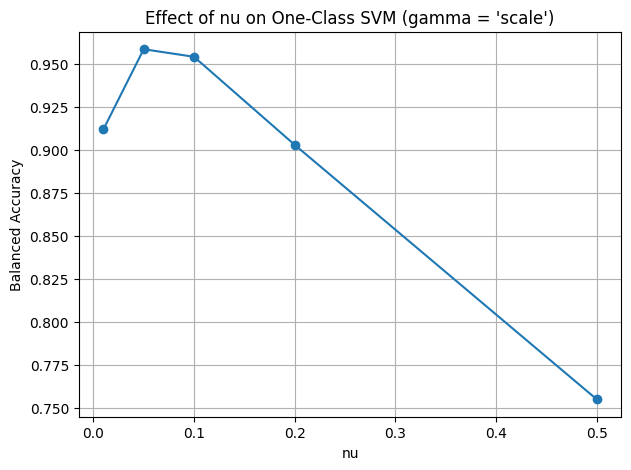

In [13]:
scale_results = results_df[
    results_df["gamma"] == "scale"
].sort_values("nu")

plt.figure(figsize=(7,5))
plt.plot(
    scale_results["nu"],
    scale_results["balanced_accuracy"],
    marker="o"
)

plt.xlabel("nu")
plt.ylabel("Balanced Accuracy")
plt.title("Effect of nu on One-Class SVM (gamma = 'scale')")
plt.grid()

plt.show()

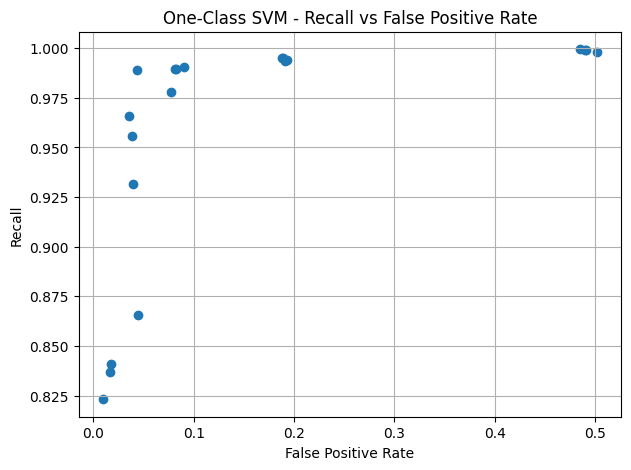

In [14]:
plt.figure(figsize=(7,5))

plt.scatter(
    results_df["fpr"],
    results_df["recall"]
)

plt.xlabel("False Positive Rate")
plt.ylabel("Recall")
plt.title("One-Class SVM - Recall vs False Positive Rate")
plt.grid()
plt.show()

The first plot (only `gamma="scale"`) shows that the Balanced Accuracy is highest around `nu=0.05` and drops quickly for larger values, because the false alarms grow.

The second plot shows all 20 configurations. Configurations with very few false alarms (bottom left) miss more attacks, while configurations with high Recall (right) produce many false alarms.

The selected configuration (`nu=0.05`, `gamma=0.1`) is the point at the top left: Recall 0.989 with a False Positive Rate of 0.044.

In [15]:
best_nu = results_df.iloc[0]["nu"]
best_gamma = results_df.iloc[0]["gamma"]

print("Selected nu:", best_nu)
print("Selected gamma:", best_gamma)

Selected nu: 0.05
Selected gamma: 0.1


### Final model and test evaluation

The final model is trained with the selected hyperparameters. The test set is used only here, once, to measure the performance on data never used for any choice.

In [16]:
final_model = OneClassSVM(
    kernel="rbf",
    nu = best_nu,
    gamma = best_gamma
)

final_model.fit(X_train)

OneClassSVM(gamma=0.1, nu=0.05)

In [17]:
test_predictions = final_model.predict(X_test)
test_predictions = (test_predictions == -1).astype(int)

test_cm = confusion_matrix(y_test, test_predictions)

tn,fp,fn,tp = test_cm.ravel()

print("Confusion Matrix:")
print(test_cm)

print("\nTrue Negaitves:", tn)
print("False Positives:", fp)
print("False Negaitves:", fn)
print("True Positives:", tp)

Confusion Matrix:
[[ 2262   141]
 [  518 52436]]

True Negaitves: 2262
False Positives: 141
False Negaitves: 518
True Positives: 52436


In [18]:
test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions)
test_recall = recall_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)

test_fpr = fp / (fp + tn)

test_scores = -final_model.decision_function(X_test)

test_roc_auc = roc_auc_score(y_test, test_scores)
test_pr_auc = average_precision_score(y_test, test_scores)

In [19]:
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)
print("F1-score:", test_f1)
print("Balanced Accuracy:", test_balanced_accuracy)
print("False Positive Rate:", test_fpr)
print("ROC-AUC:", test_roc_auc)
print("PR-AUC:", test_pr_auc)

Accuracy: 0.9880954531495565
Precision: 0.9973182189930958
Recall: 0.9902179249915021
F1-score: 0.9937553894116421
Balanced Accuracy: 0.9657706354046149
False Positive Rate: 0.05867665418227216
ROC-AUC: 0.9883311399080014
PR-AUC: 0.9993909197561642


According to the test set, the model reaches a BA of 0.966, in particular with a Recall of 0.990 and FPR of 0.059 with total of 141 false alarms out of 2403 normal samples.

The results are very close to the validation results (0.973) so the configuration generalizes well to new data.

In [20]:
attack_analysis = test_metadata.copy()
attack_analysis["Prediction"] = test_predictions

attack_analysis = attack_analysis[
    attack_analysis["Label"] == "Anomaly"
]

attack_detection = attack_analysis.groupby(
    "Attack_type"
)["Prediction"].agg(["count", "sum"])

attack_detection["detection_rate"] = (
    attack_detection["sum"] /
    attack_detection["count"]
)

attack_detection

,count,sum,detection_rate
Attack_type,,,
ARP_poisioning,3813,3300,0.865460
DDOS_Slowloris,266,266,1.000000
DOS_SYN_Hping,45045,45045,1.000000
Metasploit_Brute_Force_SSH,18,17,0.944444
NMAP_FIN_SCAN,14,13,0.928571
NMAP_OS_DETECTION,1000,1000,1.000000
NMAP_TCP_scan,501,501,1.000000
NMAP_UDP_SCAN,1292,1289,0.997678
NMAP_XMAS_TREE_SCAN,1005,1005,1.000000


Most attacks are detected almost perfectly. The hardest one is ARP_poisoning (86.5% detected): it changes the mapping between addresses but its flows look similar to normal traffic.

The small classes have very few test samples, so one missed flow changes a lot their rate.

In [21]:
normal_analysis = test_metadata.copy()
normal_analysis["Prediction"] = test_predictions
normal_analysis = normal_analysis[normal_analysis["Label"] == "Normal"]

false_alarms = normal_analysis.groupby("Attack_type")["Prediction"].agg(["count", "sum"])
false_alarms.columns = ["normal_samples", "false_alarms"] 

false_alarms["false_positive_rate"] = (
    false_alarms["false_alarms"] / false_alarms["normal_samples"]
)

false_alarms

,normal_samples,false_alarms,false_positive_rate
Attack_type,,,
MQTT_Publish,829,22,0.026538
Thing_Speak,1530,89,0.058170
Wipro_bulb,44,30,0.681818


Most false alarms come from Thing_Speak (89), the largest normal class. 

However, the highest rate is on Wipro_bulb: 30 of its 44 test samples  are flagged as attacks. 

Wipro_bulb has very few training samples, so the model does not learn its behaviour well.

In [22]:
results_df.to_csv(
    "../results/tables/one_class_svm_validation_results.csv",
    index=False
)

attack_detection.to_csv(
    "../results/tables/one_class_svm_attack_detection.csv"
)

In [23]:
tn, fp, fn, tp = test_cm.ravel()

final_metrics = pd.DataFrame([{
    "model": "One-Class SVM",
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "accuracy": test_accuracy,
    "precision": test_precision,
    "recall": test_recall,
    "f1": test_f1,
    "balanced_accuracy": test_balanced_accuracy,
    "fpr": test_fpr,
    "roc_auc": test_roc_auc,
    "pr_auc": test_pr_auc
}])

final_metrics.to_csv("../results/tables/one_class_svm_final_metrics.csv", index=False)
false_alarms.to_csv("../results/tables/one_class_svm_false_alarms.csv")
final_metrics

,model,tn,fp,fn,tp,accuracy,precision,recall,f1,balanced_accuracy,fpr,roc_auc,pr_auc
0,One-Class SVM,2262,141,518,52436,0.988095,0.997318,0.990218,0.993755,0.965771,0.058677,0.988331,0.999391


All DOS_SYN_Hping flows (about 77% of the dataset) go to destination port 21, while no normal flow does. The model could therefore detect most attacks just by looking at the port. To check this, we retrain the same model without the two port columns (`id.orig_p` and `id.resp_p`).

In [24]:
port_cols = ["id.orig_p", "id.resp_p"]

svm_no_ports = OneClassSVM(kernel = "rbf", nu = best_nu, gamma = best_gamma)
svm_no_ports.fit(X_train.drop(columns = port_cols))

no_ports_predictions = (svm_no_ports.predict(X_test.drop(columns = port_cols)) == -1).astype(int)

print("Balanced Accuracy senza porte:", balanced_accuracy_score(y_test, no_ports_predictions))
print("Recall senza porte:", recall_score(y_test, no_ports_predictions))

Balanced Accuracy senza porte: 0.9523729056937442
Recall senza porte: 0.9625901726026362


As we can see, without the port columns the Balanced Accuracy goes from 0.966 to 0.952 and the recall from 0.990 to 0.963.

The ports help a bit, but the performance remains high.

### Conclusions

- With the default `nu=0.5` the model produces too many false alarms (FPR 0.49).
- After the analysis, `nu=0.05` and `gamma=0.1` give the best balance between detected attacks and false alarms.
- On the test set: Balanced Accuracy 0.966, Recall 0.990, False Positive Rate 0.059.
- Weak points: ARP_poisoning among the attacks and Wipro_bulb among the normal devices.